# Ориентация текстового кропа: 0° или 180°

**Результат на платформе: 1 − Brier = 0.9913** (первая отправка, только CNN: 0.9643).

Ноутбук воспроизводит отправленный `submission.csv` и объясняет решение. Весь код — в модулях `src/` и скриптах `scripts/`, здесь они вызываются и комментируются.

## Описание подхода

### 1. Данные
Обучающих данных в задаче нет, а размечать тест руками запрещено. Все данные для обучения и валидации — внешние и открытые:

| Источник | Что это | Зачем |
|---|---|---|
| **TextOCR** (HF `MiXaiLL76/TextOCR_OCR`) | ~68 тыс. реальных кропов слов с фото, все в правильной ориентации | реальные фото, камера, шумы; но только латиница |
| **Синтетика** (`src/synth.py`) | кропы, отрисованные 159 OFL-шрифтами Google Fonts: фразы русской Википедии, английские слова, цены, телефоны, артикулы, даты | кириллица, которой нет в TextOCR; тест Авито в основном на русском |

Метки получаются бесплатно: кроп в правильной ориентации — это `y=0`, он же, повёрнутый на 180°, — `y=1`.

Синтетика имитирует выход детектора текста: плотный бокс с небольшими случайными отступами (иногда с обрезанным текстом или куском соседней строки), фоны (однотонные, градиенты, текстуры), обводка и тени, а также деградации: наклон, перспектива, низкое разрешение (высота 9–90 px, как в тесте), размытие, шум, JPEG.

### 2. Валидация
Тест не размечен, поэтому качество мерится на двух отложенных наборах, похожих на тест с разных сторон:
* `real_en` — 3000 кропов из **test**-сплита TextOCR (реальные фото, в обучении не использовались);
* `syn_ru` — 4000 синтетических кропов, отрисованных **отложенными шрифтами** (каждое 7-е семейство) и фразами из **отложенных статей** Википедии (последние 20%). Так проверяется обобщение на незнакомые шрифты и тексты, а не запоминание.

Половина кропов в каждом наборе повёрнута (seed фиксирован). Метрика — 1 − Brier, как на платформе. Дополнительно проверялся **перенос между доменами**: стекер, обученный на одном наборе, оценивался на другом. Тест — третий домен, поэтому важно, чтобы комбинация моделей переносилась.

### 3. Модель 1 — компактная CNN (`src/model.py`)
* Вход: кроп, приведённый к высоте 32 px с сохранением пропорций (не шире 256 px) и дополненный нулями **по центру** до 32×256, плюс маска валидных колонок.
* VGG-подобная сеть из 7 обычных свёрток 3×3 (depthwise-свёртки оказались в разы медленнее на MPS/CPU при том же качестве), попиксельная «оценка правильности» по колонкам и маскированное усреднение → скаляр `f(x)`.
* **Антисимметричная голова:** `logit = f(rot180(x)) − f(x)`. Благодаря центральному паддингу `rot180` — это просто `x.flip(2, 3)`. По построению `p(rot x) = 1 − p(x)`: модель не может противоречить сама себе, а учить ей нужно только «насколько кроп выглядит правильно стоящим».
* 0.47 млн параметров, 1.9 МБ в ONNX, ~1.6 мс/кроп на одном ядре CPU.
* Обучение: 16 000 шагов × 256 примеров, 50% синтетики и 50% TextOCR, AdamW + OneCycle, BCE. Каждый пример генерируется детерминированно из своего индекса (seed=42).
* Калибровка: одна температура `T`, минимизирующая Brier на валидации.

### 4. Модель 2 — распознаватели текста PaddleOCR как «языковой» сигнал (`src/pretrained.py`)
Готовые классификаторы ориентации PaddleOCR (PP-LCNet) обучены в основном на китайском и английском и на наших данных слабы (0.83–0.89). Зато **распознаватели** PP-OCRv5 для кириллицы (`eslav`, `cyrillic`) хорошо «знают язык»: правильно стоящий текст они читают уверенно, перевёрнутый — как мусор с низкой уверенностью. Для каждого кропа распознаватель запускается на кропе и на его повороте, и признаки — это разница между ними:
* средний log-prob распознанных символов,
* средний log max-prob по всем кадрам CTC,
* доля кадров, распознанных как символ.

### 5. Стекинг (`src/stacking.py`)
Логистическая регрессия **без свободного члена** на 7 антисимметричных признаках: логит CNN + 3 × 2 признака распознавателей. Поскольку все признаки меняют знак при повороте, итоговая модель тоже антисимметрична, и отдельная калибровка не нужна: логрегрессия сама калиброванная. CNN смотрит на форму глифов, распознаватель — на то, складываются ли символы в текст; ошибаются они на разных кропах, поэтому комбинация даёт большой прирост.

### 6. Результаты (1 − Brier)

| Модель | real_en | syn_ru | тест (платформа) |
|---|---|---|---|
| PP-LCNet x0.25 textline_ori (готовый, PaddleOCR) | 0.889 | 0.831 | — |
| распознаватель eslav PP-OCRv5 + логрег | 0.958 | 0.963 | — |
| наша CNN, ширина 16 (0.21 млн параметров) | 0.924 | 0.965 | — |
| **наша CNN, ширина 24** (0.47 млн) | 0.937 | 0.970 | **0.9643** |
| **CNN + 2 распознавателя, стекинг** (5-fold CV) | **0.969** | **0.981** | **0.9913** |

### 7. Что пробовалось и не вошло
* depthwise-separable CNN (MobileNet-стиль): то же качество, но обучение в ~6 раз медленнее на MPS;
* «контекстные» признаки стекера (насколько кроп читаем вообще, как множитель к остальным признакам): прироста нет;
* добавление в стек второй CNN (ширина 16): +0.0006, не стоит лишней модели;
* датасеты `pumb-ai/synthetic-cyrillic-large` (рукописный, украинский) и `nastyboget/*` (рукописные) — не похожи на тест, не использовались.

### 8. Производительность
Финальный пайплайн: CNN (1.9 МБ) + 2 распознавателя (по ~8 МБ, по 2 прогона на кроп). Если критична скорость, CNN одна даёт 0.964 при ~1.6 мс/кроп. Следующий логичный шаг — дистиллировать стек в одну CNN: разметить им большой пул неразмеченных кропов и дообучить маленькую модель повторять его вероятности.

### 9. Использованные open-source компоненты
* **PaddleOCR** PP-OCRv5 `eslav`/`cyrillic` mobile recognizers (Apache-2.0), ONNX-экспорт из **RapidOCR** v3.9.2;
* **TextOCR** (CC-BY 4.0) через HF `MiXaiLL76/TextOCR_OCR`; **Wikipedia** (ru, CC-BY-SA) через HF `wikimedia/wikipedia`; **Google Fonts** (OFL), зафиксированный коммит;
* PyTorch, ONNX Runtime, OpenCV, Pillow, scikit-learn.

Внешние API и LLM/VLM не используются; тест вручную не размечался и в обучении не участвовал.

## Как запустить

```bash
pip install -r requirements.txt
# положить выданные данные так:  test/test/images/*.png  и  test/sample_submission.csv
jupyter nbconvert --to notebook --execute solution.ipynb   # или Run All
```

Режимы (ячейка ниже):
* по умолчанию — **воспроизведение сабмита**: используются приложенные веса CNN (`models/w24_v1/best.pt`) и коэффициенты стекера (`models/stacker.json`); скачиваются только 2 распознавателя (16 МБ). Занимает ~10 минут на CPU.
* `REFIT_STACKER = True` — заново подобрать стекер на валидации (признаки валидации приложены в `artifacts/features/`);
* `RETRAIN = True` — полностью переобучить CNN (скачивает ~3.5 ГБ данных; ~20 мин на Apple M4 Pro / GPU, в разы дольше на слабом CPU). Переобученная на другом железе сеть будет численно немного отличаться, поэтому для точного воспроизведения сабмита приложены веса.

Структура:
```
src/common.py      пути, seed, чтение картинок, метрики, калибровка температурой
src/synth.py       генератор синтетических кропов (тексты, шрифты, фон, деградации)
src/data_real.py   загрузка реальных кропов TextOCR
src/dataset.py     torch-датасеты и фиксированные валидационные наборы
src/model.py       препроцессинг и антисимметричная CNN
src/pretrained.py  обёртки над ONNX-моделями PaddleOCR
src/stacking.py    признаки и антисимметричная логрегрессия
src/pipeline.py    инференс: кропы -> признаки -> p_180
scripts/download_data.py   скачивание внешних данных (--minimal: только для инференса)
scripts/train.py           обучение CNN (+ калибровка температуры)
scripts/fit_stacker.py     признаки валидации, оценка стекинга, models/stacker.json
scripts/make_submission.py submission.csv
scripts/export_onnx.py     экспорт CNN в ONNX и замер скорости
```

## 0. Настройки

In [1]:
import json, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RETRAIN = False        # переобучить CNN с нуля
REFIT_STACKER = False  # заново подобрать стекер на валидации

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.common import SAMPLE_SUB, TEST_DIR, read_bgr, report, rot180, seed_everything

seed_everything(42)
assert TEST_DIR.exists(), f'положите тестовые картинки в {TEST_DIR}'

def run(cmd):
    # запуск скрипта проекта с выводом в ноутбук
    print('$', cmd)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print('\n'.join(l for l in (r.stdout + r.stderr).splitlines() if 'Warning' not in l))
    assert r.returncode == 0

## 1. Внешние данные
Для воспроизведения сабмита нужны только 2 распознавателя PaddleOCR. Для переобучения — всё остальное.

In [2]:
run(f'{sys.executable} scripts/download_data.py' + ('' if RETRAIN else ' --minimal'))

$ /opt/miniconda3/bin/python3.13 scripts/download_data.py --minimal


ok models/pretrained/eslav_PP-OCRv5_rec_mobile.onnx
ok models/pretrained/cyrillic_PP-OCRv5_rec_mobile.onnx


## 2. Тестовые данные
20 000 кропов, все горизонтальные (ширина/высота ≥ 1.5), высота от 10 до ~440 px; русский и латиница, фото и скриншоты. Примерно половина перевёрнута.

20000 кропов; высота: медиана 42, 5-95% [16, 195]; ширина/высота: медиана 4.9, мин 0.7


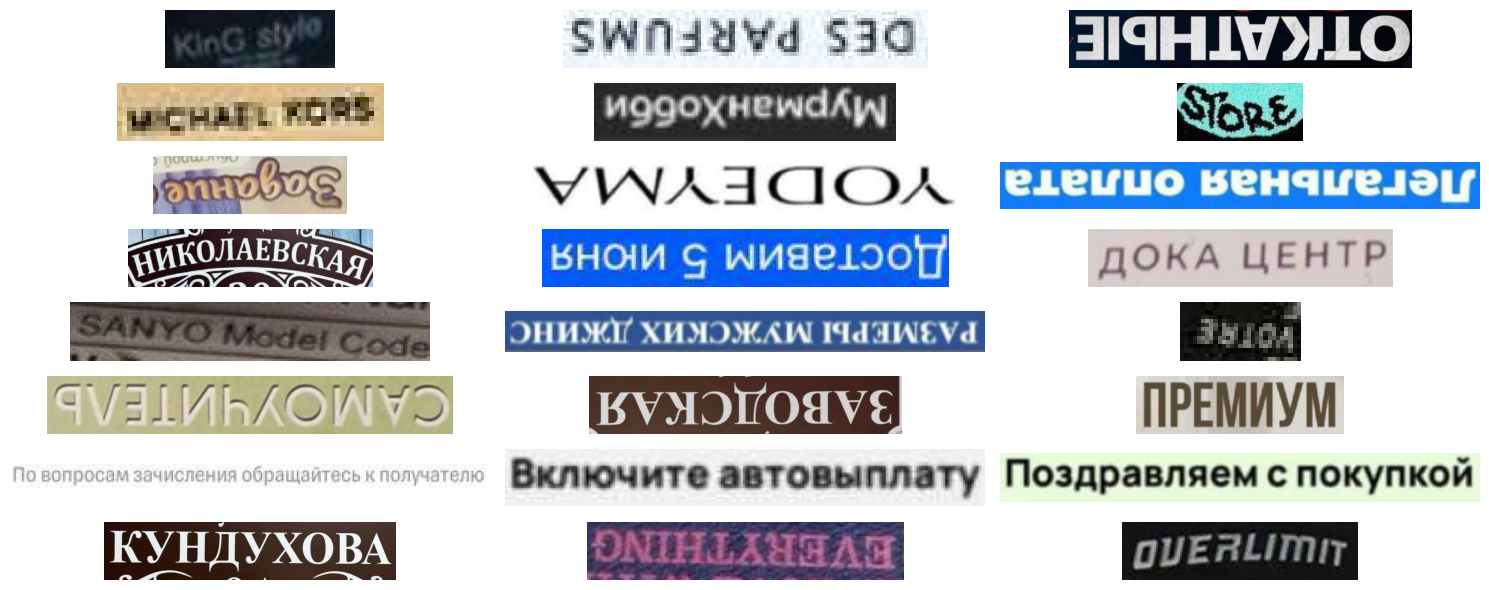

In [3]:
sub = pd.read_csv(SAMPLE_SUB)
test_imgs = [read_bgr(TEST_DIR / f'{i}.png') for i in sub.image_id]
h = np.array([im.shape[0] for im in test_imgs]); ar = np.array([im.shape[1] / im.shape[0] for im in test_imgs])
print(f'{len(test_imgs)} кропов; высота: медиана {np.median(h):.0f}, 5-95% [{np.percentile(h,5):.0f}, {np.percentile(h,95):.0f}]; '
      f'ширина/высота: медиана {np.median(ar):.1f}, мин {ar.min():.1f}')

fig, axes = plt.subplots(8, 3, figsize=(15, 6))
for ax, im in zip(axes.ravel(), test_imgs[:24]):
    ax.imshow(im[:, :, ::-1]); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Синтетика (только при `RETRAIN=True`, нужны шрифты и Википедия)
Примеры сгенерированных кропов, все в правильной ориентации (переворот делается при обучении).

In [4]:
if RETRAIN:
    import random
    from src.synth import Renderer, TextSampler, list_fonts
    R = Renderer(list_fonts('train'), TextSampler('train', n_docs=3000))
    r = random.Random(0)
    fig, axes = plt.subplots(8, 3, figsize=(15, 6))
    for ax in axes.ravel():
        ax.imshow(R.render(r)[:, :, ::-1]); ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('пропущено (RETRAIN=False)')

пропущено (RETRAIN=False)


## 4. CNN
Архитектура и кривые обучения финальной модели (`models/w24_v1`). При `RETRAIN=True` модель обучается заново тем же скриптом с теми же параметрами.

OrientNet(
  (features): Sequential(
    (0): ConvBNAct(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): ConvBNAct(
      (0): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): ConvBNAct(
      (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (3): ConvBNAct(
      (0): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): R

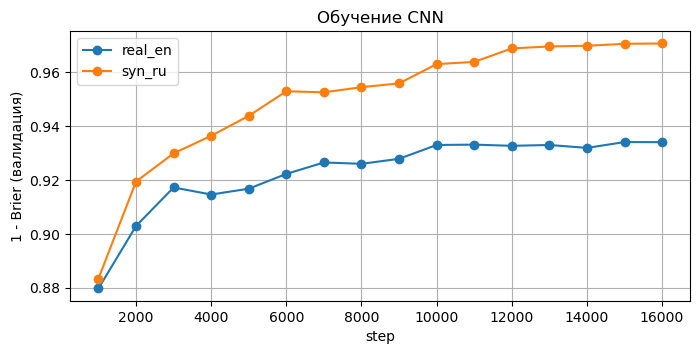

In [5]:
if RETRAIN:
    run(f'{sys.executable} scripts/train.py --name w24_v1 --width 24 --steps 16000 --p_synth 0.5 --eval_every 1000')

from src.model import n_params
from src.pipeline import CNN_DIR, load_cnn
cnn = load_cnn()
print(cnn)
print('параметров:', n_params(cnn))
print('калибровка:', json.loads((CNN_DIR / 'calibration.json').read_text())['temperature'])

hist = pd.DataFrame(json.loads((CNN_DIR / 'history.json').read_text()))
ax = hist.plot(x='step', y=['real_en', 'syn_ru'], marker='o', figsize=(8, 3.5), grid=True)
ax.set_ylabel('1 - Brier (валидация)'); ax.set_title('Обучение CNN'); plt.show()

### Проверка антисимметрии
Предсказание для повёрнутого кропа должно быть `1 − p` для исходного: логиты x и rot180(x) равны с обратным знаком (с точностью до интерполяции при ресайзе).

In [6]:
from src.pipeline import cnn_logits
l = cnn_logits(cnn, test_imgs[:200]); l_rot = cnn_logits(cnn, [rot180(im) for im in test_imgs[:200]])
print('max |logit(x) + logit(rot x)| =', np.abs(l + l_rot).max())

max |logit(x) + logit(rot x)| = 0.009136915


## 5. Стекинг CNN + распознаватели PaddleOCR
Оценка на валидации: CNN отдельно, стек с переносом между доменами и 5-fold CV. Признаки валидации приложены в `artifacts/features/` (их можно пересчитать, удалив файлы: `scripts/fit_stacker.py` сгенерирует валидацию заново).

In [7]:
from src.stacking import AntisymLR, build_features
from src.pipeline import STACKER_PATH
from sklearn.model_selection import StratifiedKFold

if REFIT_STACKER:
    run(f'{sys.executable} scripts/fit_stacker.py')

D = {k: dict(np.load(f'artifacts/features/{k}.npz')) for k in ['real_en', 'syn_ru']}
X = {k: build_features(d) for k, d in D.items()}; y = {k: d['y'] for k, d in D.items()}
T = json.loads((CNN_DIR / 'calibration.json').read_text())['temperature']

print('CNN (калиброванная):')
for k in D: report('  ' + k, 1 / (1 + np.exp(-D[k]['cnn'] / T)), y[k])
print('стек, перенос между доменами:')
for a, b in [('real_en', 'syn_ru'), ('syn_ru', 'real_en')]:
    report(f'  fit {a} -> {b}', AntisymLR().fit(X[a], y[a]).predict(X[b]), y[b])
print('стек, 5-fold CV на объединении:')
Xu, yu = np.concatenate(list(X.values())), np.concatenate(list(y.values()))
grp = np.concatenate([[k] * len(y[k]) for k in y]); p = np.zeros(len(yu))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(Xu, yu):
    p[te] = AntisymLR().fit(Xu[tr], yu[tr]).predict(Xu[te])
for k in y: report('  ' + k, p[grp == k], yu[grp == k])

stacker = AntisymLR.load(STACKER_PATH)
names = ['cnn'] + [f'{m}:{f}' for m in ['eslav', 'cyr'] for f in ['charLogP', 'frameLogP', 'charShare']]
print('\nкоэффициенты финального стекера (на признак / масштаб):')
print(pd.Series(stacker.lr.coef_[0] / stacker.mu, index=names).round(3).to_string())

CNN (калиброванная):
  real_en                                1-Brier=0.9367 acc=0.9133 logloss=0.2313 n=3000
  syn_ru                                 1-Brier=0.9702 acc=0.9587 logloss=0.0989 n=4000
стек, перенос между доменами:
  fit real_en -> syn_ru                  1-Brier=0.9776 acc=0.9738 logloss=0.0845 n=4000
  fit syn_ru -> real_en                  1-Brier=0.9693 acc=0.9603 logloss=0.1593 n=3000
стек, 5-fold CV на объединении:
  real_en                                1-Brier=0.9693 acc=0.9607 logloss=0.1323 n=3000
  syn_ru                                 1-Brier=0.9813 acc=0.9785 logloss=0.0667 n=4000

коэффициенты финального стекера (на признак / масштаб):
cnn                0.360
eslav:charLogP    -0.650
eslav:frameLogP   -0.599
eslav:charShare   -3.695
cyr:charLogP      -0.542
cyr:frameLogP     -1.287
cyr:charShare     -4.246


## 6. Предсказание для теста → `submission.csv`
CNN + 2 распознавателя (каждый на кропе и его повороте) + стекер. ~8 минут на CPU.

In [8]:
from src.pipeline import compute_features, predict_proba
t0 = time.time()
feats = compute_features(test_imgs, cnn)
print(f'признаки: {time.time() - t0:.0f} c')
sub['p_180'] = predict_proba(feats, stacker)
sub[['image_id', 'p_180']].to_csv('submission.csv', index=False)
print(sub.head(), '\nдоля p_180 > 0.5:', (sub.p_180 > 0.5).mean().round(3))

  rec_eslav: done


  rec_cyr: done


признаки: 371 c
     image_id     p_180
0  test_00000  0.000624
1  test_00001  0.999860
2  test_00002  0.997953
3  test_00003  0.007121
4  test_00004  0.992204 
доля p_180 > 0.5: 0.5


### Совпадение с отправленным файлом
Отправленный на платформу файл лежит в `submissions/submission_2_final.csv`.

In [9]:
ref = pd.read_csv('submissions/submission_2_final.csv')
assert (ref.image_id == sub.image_id).all()
print('max |p - p_submitted| =', np.abs(ref.p_180.values - sub.p_180.values).max())

max |p - p_submitted| = 1.1102230246251565e-16


## 7. Размер и скорость

In [10]:
import torch
from src.pretrained import RecScorer
from src.pipeline import REC_MODELS
from src.common import PRETRAINED_DIR

torch.set_num_threads(1)
sample = test_imgs[:500]
t0 = time.time(); cnn_logits(cnn, sample); t_cnn = (time.time() - t0) / len(sample) * 1000
t_rec = 0
for name in REC_MODELS.values():
    t0 = time.time(); RecScorer(name, threads=1).features(sample); t_rec += (time.time() - t0) / len(sample) * 1000
cnn_mb = (CNN_DIR / 'best.pt').stat().st_size / 1e6
rec_mb = sum((PRETRAINED_DIR / n).stat().st_size for n in REC_MODELS.values()) / 1e6
print(pd.DataFrame({'размер, МБ': [cnn_mb, rec_mb, cnn_mb + rec_mb],
                    'мс/кроп, 1 поток CPU': [t_cnn, t_rec, t_cnn + t_rec]},
                   index=['CNN (PyTorch)', '2 распознавателя x 2 прогона', 'итого']).round(2))

                              размер, МБ  мс/кроп, 1 поток CPU
CNN (PyTorch)                       1.89                  2.77
2 распознавателя x 2 прогона       15.99                 81.05
итого                              17.88                 83.82
